# DOE-003
## トレーリング・ストップ調査 - 基礎調査
- 対象銘柄: 9984
- PPF (Pure Pursuit Folloewer) vs SMA vs EMA
- トレーリング・ストップ利確
    -  START_TRAINING: トレーリングを始める最大含み益
    -  THRESHOLD_TRAILING: トレーリング・ストップするしきい値
- クロス・シグナルのエントリ・エグジット
- 評価指標
    - 収益と約定回数

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
name_doe = "doe-003"
date_trade = "20260908"
name_code = "9984"
csvfile = f"../doe/{name_doe}/{date_trade}_{name_code}.csv"
df = pd.read_csv(csvfile)
df

,TYPE_MA_1,PERIOD_MA_1,START_TRAILING,THRESHOLD_TRAILING,Profit,Transactions
0,PPF,5,10,0.1,-5.0,2.0
1,PPF,5,10,0.2,-5.0,2.0
2,PPF,5,10,0.3,-5.0,2.0
3,PPF,5,10,0.4,-5.0,2.0
4,PPF,5,10,0.5,-5.0,2.0
...,...,...,...,...,...,...
319,EMA,45,60,0.5,-6.0,2.0
320,EMA,45,60,0.6,-6.0,2.0
321,EMA,45,60,0.7,-6.0,2.0
322,EMA,45,60,0.8,-6.0,2.0


In [8]:
profit_max = df["Profit"].max()
df[df["Profit"] == profit_max]

,TYPE_MA_1,PERIOD_MA_1,START_TRAILING,THRESHOLD_TRAILING,Profit,Transactions
9,SMA,30,10,0.1,-1.0,2.0
10,SMA,30,10,0.2,-1.0,2.0
11,SMA,30,10,0.3,-1.0,2.0
12,SMA,30,10,0.4,-1.0,2.0
13,SMA,30,10,0.5,-1.0,2.0
14,SMA,30,10,0.6,-1.0,2.0
15,SMA,30,10,0.7,-1.0,2.0
16,SMA,30,10,0.8,-1.0,2.0
17,SMA,30,10,0.9,-1.0,2.0
63,SMA,30,20,0.1,-1.0,2.0


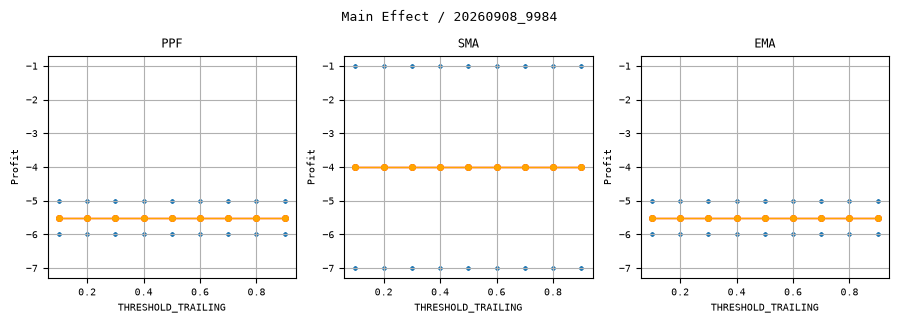

In [4]:
plt.rcParams["font.family"] = "monospace"
plt.rcParams["font.size"] = 7

fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))

name_x = "THRESHOLD_TRAILING"
name_y = "Profit"
y_min0 = df[name_y].min()
y_max0 = df[name_y].max()
pad = (y_max0 - y_min0) * 0.05
y_min = y_min0 - pad
y_max = y_max0 + pad
list_type = ["PPF", "SMA", "EMA"]
for ax, name_type in zip(axes, list_type):
    df1 = df[df["TYPE_MA_1"] == name_type]
    ax.scatter(df1[name_x], df1[name_y], s=3)

    # x の各水準ごとの平均値
    mean = df1.groupby(name_x)[name_y].mean()
    # 平均値を線で結ぶ
    ax.plot(
        mean.index,
        mean.values,
        "o-",
        color="red",
        markersize=4,
        linewidth=1,
    )
    # x の各水準ごとのメジアン
    median = df1.groupby(name_x)[name_y].median()
    # 平均値を線で結ぶ
    ax.plot(
        median.index,
        median.values,
        "o-",
        color="orange",
        markersize=4,
        linewidth=1,
    )
    
    ax.set_title(name_type)
    ax.set(xlabel=name_x, ylabel=name_y)
    ax.set_ylim(y_min, y_max)
    ax.grid(True)

fig.suptitle(f"Main Effect / {date_trade}_{name_code}", fontsize=9)

plt.tight_layout()
pngfile = f"../doe/{name_doe}/{date_trade}_{name_code}_main_effect_{name_x}_{name_y}.png"
plt.savefig(pngfile)
plt.show()

/tmp/ipykernel_52332/3783251011.py:43: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(y_min, y_max)
/tmp/ipykernel_52332/3783251011.py:43: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(y_min, y_max)
/tmp/ipykernel_52332/3783251011.py:43: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(y_min, y_max)


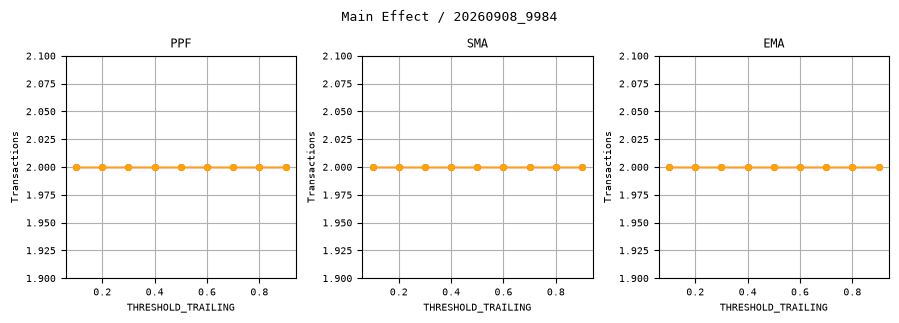

In [5]:
plt.rcParams["font.family"] = "monospace"
plt.rcParams["font.size"] = 7

fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))

name_x = "THRESHOLD_TRAILING"
name_y = "Transactions"
y_min0 = df[name_y].min()
y_max0 = df[name_y].max()
pad = (y_max0 - y_min0) * 0.05
y_min = y_min0 - pad
y_max = y_max0 + pad
list_type = ["PPF", "SMA", "EMA"]
for ax, name_type in zip(axes, list_type):
    df1 = df[df["TYPE_MA_1"] == name_type]
    ax.scatter(df1[name_x], df1[name_y], s=3)

    # x の各水準ごとの平均値
    mean = df1.groupby(name_x)[name_y].mean()
    # 平均値を線で結ぶ
    ax.plot(
        mean.index,
        mean.values,
        "o-",
        color="red",
        markersize=4,
        linewidth=1,
    )
    # x の各水準ごとのメジアン
    median = df1.groupby(name_x)[name_y].median()
    # 平均値を線で結ぶ
    ax.plot(
        median.index,
        median.values,
        "o-",
        color="orange",
        markersize=4,
        linewidth=1,
    )
    
    ax.set_title(name_type)
    ax.set(xlabel=name_x, ylabel=name_y)
    ax.set_ylim(y_min, y_max)
    ax.grid(True)

fig.suptitle(f"Main Effect / {date_trade}_{name_code}", fontsize=9)

plt.tight_layout()
pngfile = f"../doe/{name_doe}/{date_trade}_{name_code}_main_effect_{name_x}_{name_y}.png"
plt.savefig(pngfile)
plt.show()

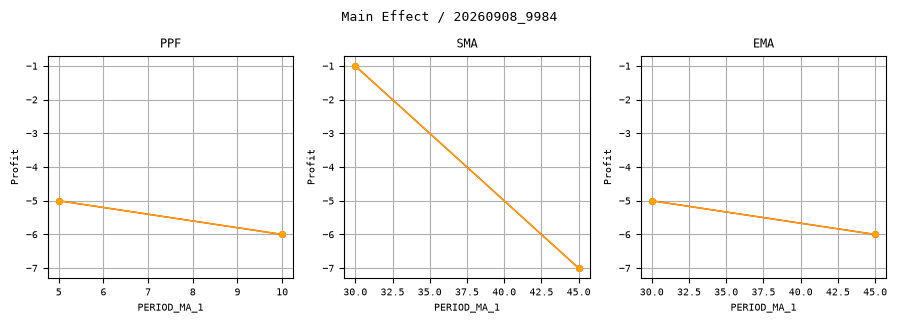

In [6]:
plt.rcParams["font.family"] = "monospace"
plt.rcParams["font.size"] = 7

fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))

name_x = "PERIOD_MA_1"
name_y = "Profit"
y_min0 = df[name_y].min()
y_max0 = df[name_y].max()
pad = (y_max0 - y_min0) * 0.05
y_min = y_min0 - pad
y_max = y_max0 + pad
list_type = ["PPF", "SMA", "EMA"]
for ax, name_type in zip(axes, list_type):
    df1 = df[df["TYPE_MA_1"] == name_type]
    ax.scatter(df1[name_x], df1[name_y], s=3)

    # x の各水準ごとの平均値
    mean = df1.groupby(name_x)[name_y].mean()
    # 平均値を線で結ぶ
    ax.plot(
        mean.index,
        mean.values,
        "o-",
        color="red",
        markersize=4,
        linewidth=1,
    )
    # x の各水準ごとのメジアン
    median = df1.groupby(name_x)[name_y].median()
    # 平均値を線で結ぶ
    ax.plot(
        median.index,
        median.values,
        "o-",
        color="orange",
        markersize=4,
        linewidth=1,
    )
    
    ax.set_title(name_type)
    ax.set(xlabel=name_x, ylabel=name_y)
    ax.set_ylim(y_min, y_max)
    ax.grid(True)

fig.suptitle(f"Main Effect / {date_trade}_{name_code}", fontsize=9)

plt.tight_layout()
pngfile = f"../doe/{name_doe}/{date_trade}_{name_code}_main_effect_{name_x}_{name_y}.png"
plt.savefig(pngfile)
plt.show()

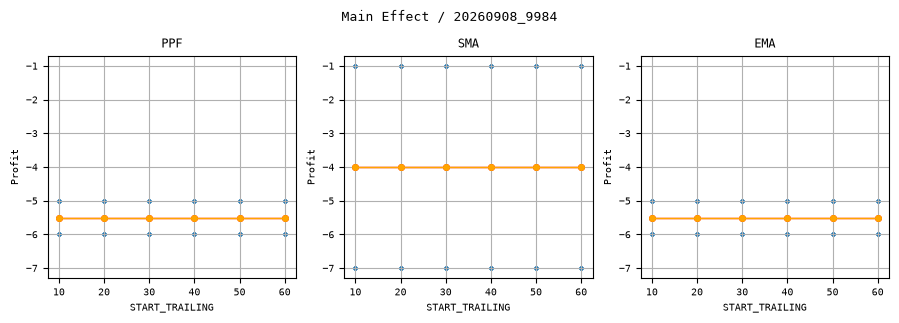

In [7]:
plt.rcParams["font.family"] = "monospace"
plt.rcParams["font.size"] = 7

fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))

name_x = "START_TRAILING"
name_y = "Profit"
y_min0 = df[name_y].min()
y_max0 = df[name_y].max()
pad = (y_max0 - y_min0) * 0.05
y_min = y_min0 - pad
y_max = y_max0 + pad
list_type = ["PPF", "SMA", "EMA"]
for ax, name_type in zip(axes, list_type):
    df1 = df[df["TYPE_MA_1"] == name_type]
    ax.scatter(df1[name_x], df1[name_y], s=3)

    # x の各水準ごとの平均値
    mean = df1.groupby(name_x)[name_y].mean()
    # 平均値を線で結ぶ
    ax.plot(
        mean.index,
        mean.values,
        "o-",
        color="red",
        markersize=4,
        linewidth=1,
    )
    # x の各水準ごとのメジアン
    median = df1.groupby(name_x)[name_y].median()
    # 平均値を線で結ぶ
    ax.plot(
        median.index,
        median.values,
        "o-",
        color="orange",
        markersize=4,
        linewidth=1,
    )
    
    ax.set_title(name_type)
    ax.set(xlabel=name_x, ylabel=name_y)
    ax.set_ylim(y_min, y_max)
    ax.grid(True)

fig.suptitle(f"Main Effect / {date_trade}_{name_code}", fontsize=9)

plt.tight_layout()
pngfile = f"../doe/{name_doe}/{date_trade}_{name_code}_main_effect_{name_x}_{name_y}.png"
plt.savefig(pngfile)
plt.show()